# House Price Prediction Using Machine Learning: A Comparative Analysis

## Problem Statement
The objective of this project is to predict house sale prices using machine learning regression algorithms. The project compares multiple models to identify the most suitable model for predicting house prices based on property characteristics.

## Dataset
King County House Sales Dataset, containing house sales records and property features.

Dataset source: https://www.kaggle.com/datasets/harlfoxem/housesalesprediction

## Objectives
1. Load and explore the dataset.
2. Perform data cleaning and exploratory data analysis.
3. Train Linear Regression, K-Nearest Neighbors, Decision Tree, and Random Forest models.
4. Tune selected models using GridSearchCV.
5. Compare models using MAE, RMSE, and R² score.
6. Save the best model for use in a Streamlit web application.


In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Exception:
Traceback (most recent call last):
  File "c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\urllib3\response.py", line 899, in _error_catcher
    yield
  File "c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\urllib3\response.py", line 1016, in _raw_read
    data = self._fp_read(amt, read1=read1) if not fp_closed else b""
           ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\urllib3\response.py", line 999, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ~~~~~~~~~~~~~^^^^^
  File "c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 100, in read
    data: bytes = self.__fp.read(amt)
    

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
os.makedirs("data", exist_ok=True)
df = pd.read_csv("data/House Data.csv")

In [9]:
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (21613, 21)


,id,date,SalePrice,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [10]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical Summary:")
display(df.describe())

Column Names:
['id', 'date', 'SalePrice', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   SalePrice      21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  


,Missing Values
id,0
date,0
SalePrice,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0



Statistical Summary:


,id,SalePrice,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [11]:
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "grade",
    "yr_built"
]

target = "SalePrice"

required_columns = features + [target]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df[required_columns].copy()

df[target] = pd.to_numeric(df[target], errors="coerce")

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(subset=[target], inplace=True)
df = df[df[target] > 0]

print("Cleaned Dataset Shape:", df.shape)
display(df.head())

Cleaned Dataset Shape: (21613, 11)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,yr_built,SalePrice
0,3,1.00,1180,5650,1.0,0,0,3,7,1955,221900.0
1,3,2.25,2570,7242,2.0,0,0,3,7,1951,538000.0
2,2,1.00,770,10000,1.0,0,0,3,6,1933,180000.0
3,4,3.00,1960,5000,1.0,0,0,5,7,1965,604000.0
4,3,2.00,1680,8080,1.0,0,0,3,8,1987,510000.0


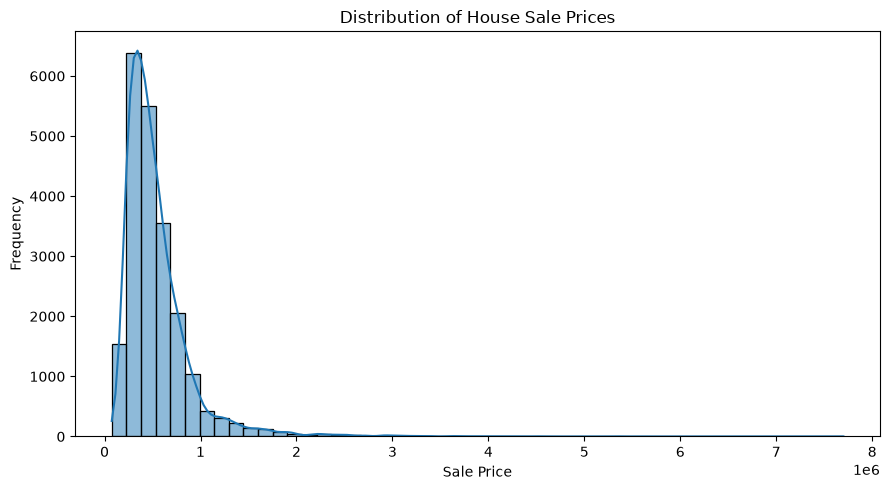

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(df["SalePrice"], bins=50, kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("outputs/figures/price_distribution.png")
plt.show()

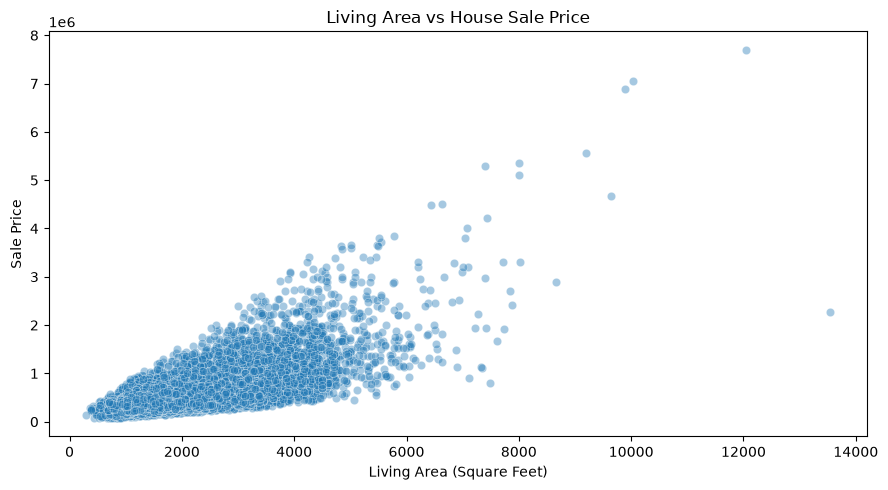

In [13]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="sqft_living",
    y="SalePrice",
    alpha=0.4
)
plt.title("Living Area vs House Sale Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.savefig("outputs/figures/living_area_vs_price.png")
plt.show()

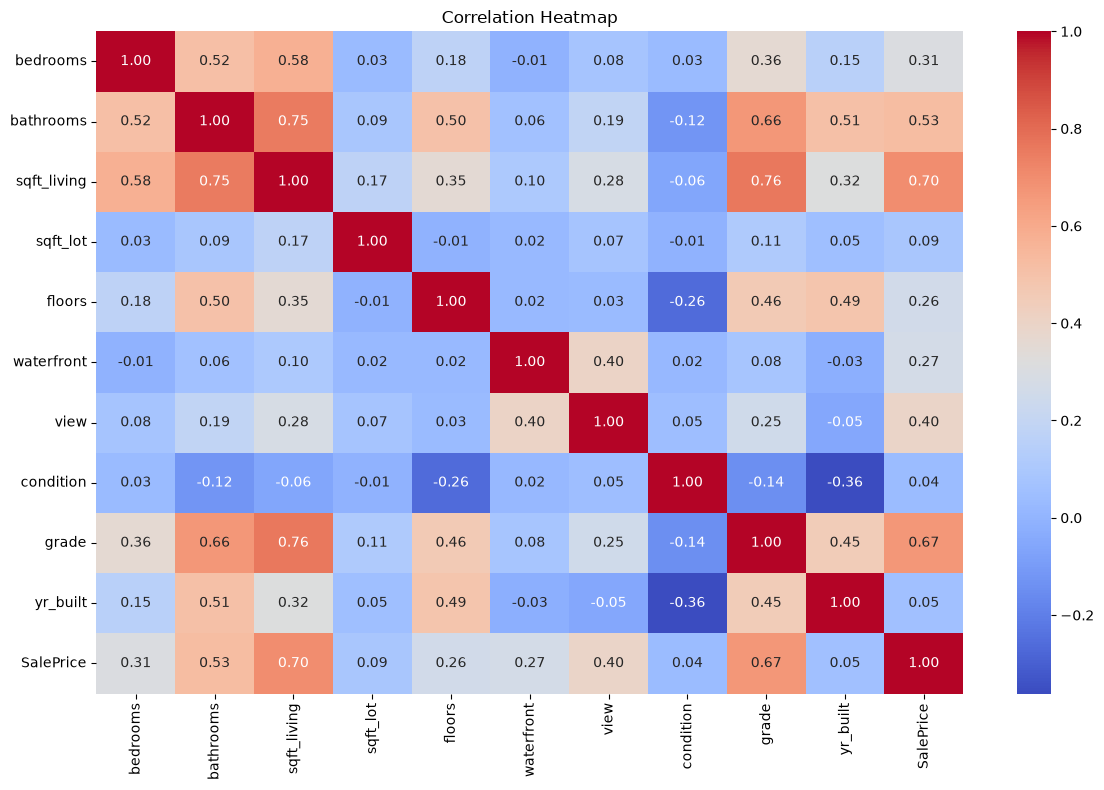

In [14]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df[features + [target]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("outputs/figures/correlation_heatmap.png")
plt.show()

In [15]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training samples: 17290
Testing samples: 4323
Number of input features: 10


In [16]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor())
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

baseline_results = pd.DataFrame(results)
display(baseline_results.round(3))

Training: Linear Regression
Training: KNN
Training: Decision Tree
Training: Random Forest


,Model,MAE,RMSE,R2 Score
0,Linear Regression,143710.477,229315.388,0.652
1,KNN,141029.962,229046.806,0.653
2,Decision Tree,168560.620,280947.705,0.478
3,Random Forest,128075.027,217569.696,0.687


In [17]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

knn_params = {
    "model__n_neighbors": [5, 10, 15],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

best_knn = knn_grid.best_estimator_

print("Best KNN Parameters:", knn_grid.best_params_)
print("Best KNN CV MAE:", -knn_grid.best_score_)

Best KNN Parameters: {'model__n_neighbors': 15, 'model__weights': 'distance'}
Best KNN CV MAE: 126058.4717115677


In [18]:
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_params = {
    "model__n_estimators": [100, 150],
    "model__max_depth": [15, 20]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_

print("Best Random Forest Parameters:", rf_grid.best_params_)
print("Best Random Forest CV MAE:", -rf_grid.best_score_)

Best Random Forest Parameters: {'model__max_depth': 15, 'model__n_estimators': 150}
Best Random Forest CV MAE: 122052.64297217822


In [19]:
all_models = {
    **trained_models,
    "Tuned KNN": best_knn,
    "Tuned Random Forest": best_rf
}

final_results = []

for name, model in all_models.items():
    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(final_results)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

display(results_df.round(3))

results_df.to_csv("outputs/results/model_comparison.csv", index=False)

best_model_name = results_df.iloc[0]["Model"]
best_model = all_models[best_model_name]

print("Best model by test MAE:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Tuned Random Forest,127869.028,214038.247,0.697
1,Random Forest,128075.027,217569.696,0.687
2,Tuned KNN,132635.055,219739.882,0.681
3,KNN,141029.962,229046.806,0.653
4,Linear Regression,143710.477,229315.388,0.652
5,Decision Tree,168560.620,280947.705,0.478


Best model by test MAE: Tuned Random Forest


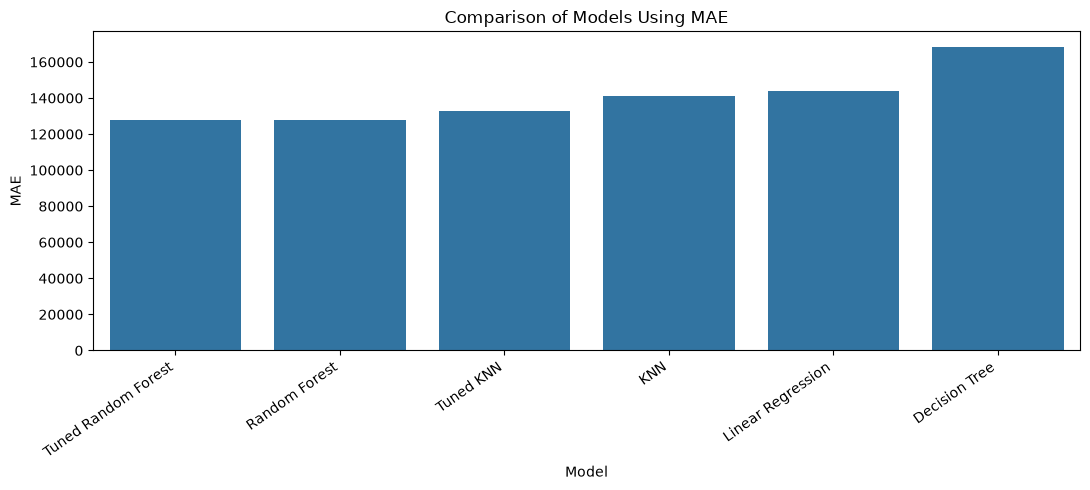

In [20]:
plt.figure(figsize=(11, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Comparison of Models Using MAE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("outputs/figures/model_mae_comparison.png")
plt.show()

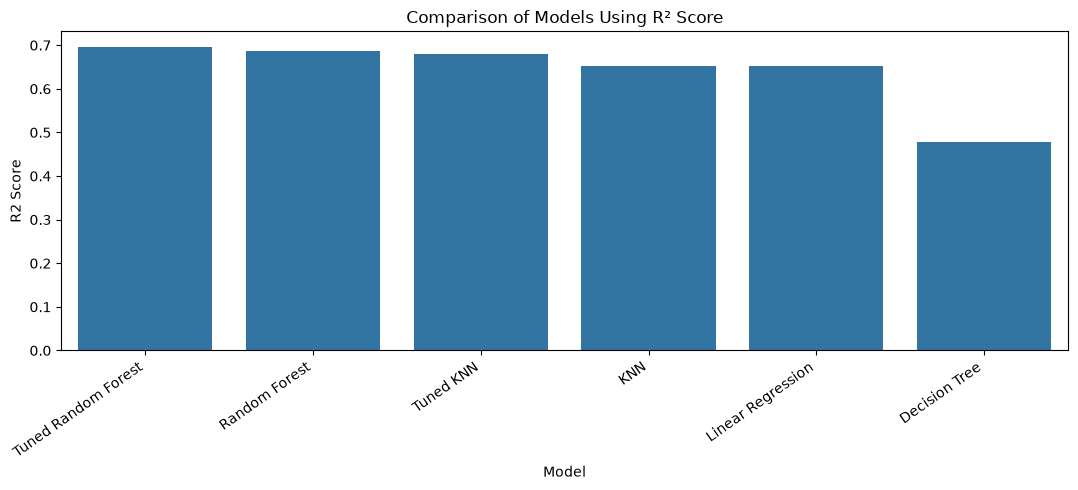

In [21]:
plt.figure(figsize=(11, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("Comparison of Models Using R² Score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("outputs/figures/model_r2_comparison.png")
plt.show()

In [22]:
joblib.dump(best_model, "models/best_model.pkl")

print("Best model:", best_model_name)
print("Saved to models/best_model.pkl")

Best model: Tuned Random Forest
Saved to models/best_model.pkl


In [23]:
sample_house = pd.DataFrame([{
    "bedrooms": 3,
    "bathrooms": 2.5,
    "sqft_living": 1800,
    "sqft_lot": 5000,
    "floors": 1.5,
    "waterfront": 0,
    "view": 0,
    "condition": 3,
    "grade": 7,
    "yr_built": 1990
}], columns=features)

loaded_model = joblib.load("models/best_model.pkl")
predicted_price = loaded_model.predict(sample_house)[0]

print(f"Predicted house price: ${predicted_price:,.2f}")

Predicted house price: $372,882.81


In [24]:
assert os.path.exists("models/best_model.pkl")
assert list(sample_house.columns) == features

loaded_model = joblib.load("models/best_model.pkl")
test_prediction = loaded_model.predict(sample_house)

print("Model loaded successfully.")
print("Input feature count:", len(features))
print("Test prediction:", f"${test_prediction[0]:,.2f}")
print("\nProject output files:")

for root, dirs, files_list in os.walk("outputs"):
    for filename in files_list:
        print(os.path.join(root, filename))

Model loaded successfully.
Input feature count: 10
Test prediction: $372,882.81

Project output files:
outputs\figures\correlation_heatmap.png
outputs\figures\living_area_vs_price.png
outputs\figures\model_mae_comparison.png
outputs\figures\model_r2_comparison.png
outputs\figures\price_distribution.png
outputs\results\model_comparison.csv
